<a href="https://colab.research.google.com/github/MakhloufiMahdi/customer-churn-intelligence-platform/blob/main/notebooks/04_feature_engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

# Load dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

# Clean TotalCharges
df["TotalCharges"] = df["TotalCharges"].replace(" ", np.nan)
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Handle missing values for new customers
df.loc[
    (df["TotalCharges"].isna()) & (df["tenure"] == 0),
    "TotalCharges"
] = 0

# Display dataset information
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (7043, 21)

Missing values:
0

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Separate target and features

target = "Churn"

X = df.drop(columns=["customerID", "Churn"])
y = df[target]

# Display dimensions
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts())

print("\nNumerical features:")
print(X.select_dtypes(include=["int64", "float64"]).columns.tolist())

print("\nCategorical features:")
print(X.select_dtypes(include=["object"]).columns.tolist())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:


,count
Churn,
No,5174
Yes,1869



Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [3]:
# Encode target variable

y = y.map({
    "No": 0,
    "Yes": 1
})

# Verify encoding
print("Target values:")
print(y.value_counts())

print("\nTarget data type:")
print(y.dtype)

print("\nFirst 10 values:")
print(y.head(10).tolist())

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64

Target data type:
int64

First 10 values:
[0, 0, 1, 0, 1, 1, 0, 0, 1, 0]


In [4]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 4
Number of categorical features: 15


In [5]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Numerical preprocessing
numeric_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    drop="first"
)

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [6]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

Training set: (5634, 19)
Testing set: (1409, 19)

Training target distribution:


,proportion
Churn,
0,73.46
1,26.54



Testing target distribution:


,proportion
Churn,
0,73.46
1,26.54


In [7]:
# Fit and transform training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

# Display shapes
print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)

print("\nPreprocessing completed successfully!")

X_train_processed shape: (5634, 30)
X_test_processed shape: (1409, 30)

Preprocessing completed successfully!


In [8]:
import numpy as np

# Check missing values
print("Missing values in train:", np.isnan(X_train_processed).sum())
print("Missing values in test:", np.isnan(X_test_processed).sum())

# Check infinite values
print("Infinite values in train:", np.isinf(X_train_processed).sum())
print("Infinite values in test:", np.isinf(X_test_processed).sum())

# Check target dimensions
print("\nTarget train shape:", y_train.shape)
print("Target test shape:", y_test.shape)

Missing values in train: 0
Missing values in test: 0
Infinite values in train: 0
Infinite values in test: 0

Target train shape: (5634,)
Target test shape: (1409,)


In [9]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
log_reg = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train model
log_reg.fit(X_train_processed, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict customer churn
y_pred = log_reg.predict(X_test_processed)

# Predict churn probabilities
y_proba = log_reg.predict_proba(X_test_processed)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predict customer churn
y_pred = log_reg.predict(X_test_processed)

# Predict churn probabilities
y_proba = log_reg.predict_proba(X_test_processed)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


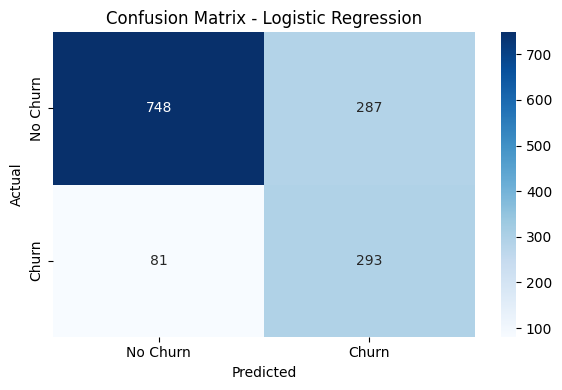

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.tight_layout()
plt.show()